**Regression on the Energy Efficiency Dataset**

**Course:** Intro to Data Science (IT803A)
**Student:** Mohammad Khizar Imran

**Goal:** predict a building's **Heating Load** and **Cooling Load** (kWh/m²) from 8 design features,

**Tasks:** Compare classical regression models with a neural network, track experiments with MLflow, and deploy the model.

Dataset: [UCI Energy Efficiency](https://archive.ics.uci.edu/dataset/242/energy+efficiency)

## Part 1 - Data Preparation & EDA

We need to import the important libraries which will be used throughout the notebook. Matplotlib is used for drawing the canvas and the labels whereas seaborn (built on matplotlib) is used to draw a polished version of the graphs/plots.

We will be importing the dataset first we have in the csv format and then we identify:
- Target features - the ones for which the predictions will be made.
- Features - the ones through which we will predict the targets.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

sns.set_theme(style="whitegrid", context="notebook")
HEAT, COOL, BLUE = "#eb6834", "#2a78d6", "#2a78d6"   # heating = orange, cooling = blue

df = pd.read_csv("data/energy_efficiency_data.csv")
TARGETS  = ["Heating_Load", "Cooling_Load"]
FEATURES = [c for c in df.columns if c not in TARGETS]
df.head()

,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load,Cooling_Load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


Now, when we do EDA (Exploratory Data Analysis) we check **3** things:
1. Is the data clean?
2. What does the data looks like?
3. How does the input features affect the target features.

In order to answer these **3** questions, we perform **7 steps**:
1. Structure and Statistics Summary - What's inside the table?
2. Missing & Duplicate values
3. Distributions - Normal or Skewed?
4. Outliers (if any)
5. Relationship between the features and target - to know which feature affects the target the most and make sure to feed that feature values in to the model.
6. Multicolinearity - do some features repeat each others information?
7. Decisions - What features to feed the model.

### 1. Structure and Statistics summary

In [2]:
print("Shape:", df.shape)
df.info()

Shape: (768, 10)
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Relative_Compactness       768 non-null    float64
 1   Surface_Area               768 non-null    float64
 2   Wall_Area                  768 non-null    float64
 3   Roof_Area                  768 non-null    float64
 4   Overall_Height             768 non-null    float64
 5   Orientation                768 non-null    int64  
 6   Glazing_Area               768 non-null    float64
 7   Glazing_Area_Distribution  768 non-null    int64  
 8   Heating_Load               768 non-null    float64
 9   Cooling_Load               768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB


We used **two methods** of pandas to get some information about our data:
1. ```.shape``` - tells us about the number of rows and cols present in our dataset (rows,cols)
2. ```.info``` - tells us if there are any missing values present in the cols and the data type of cols.

In [3]:
pd.concat([df.describe().T.round(2), df.nunique().rename("n_unique")], axis=1)

,count,mean,std,min,25%,50%,75%,max,n_unique
Relative_Compactness,768.0,0.76,0.11,0.62,0.68,0.75,0.83,0.98,12
Surface_Area,768.0,671.71,88.09,514.50,606.38,673.75,741.12,808.50,12
Wall_Area,768.0,318.50,43.63,245.00,294.00,318.50,343.00,416.50,7
Roof_Area,768.0,176.60,45.17,110.25,140.88,183.75,220.50,220.50,4
Overall_Height,768.0,5.25,1.75,3.50,3.50,5.25,7.00,7.00,2
Orientation,768.0,3.50,1.12,2.00,2.75,3.50,4.25,5.00,4
Glazing_Area,768.0,0.23,0.13,0.00,0.10,0.25,0.40,0.40,4
Glazing_Area_Distribution,768.0,2.81,1.55,0.00,1.75,3.00,4.00,5.00,6
Heating_Load,768.0,22.31,10.09,6.01,12.99,18.95,31.67,43.10,586
Cooling_Load,768.0,24.59,9.51,10.90,15.62,22.08,33.13,48.03,636


The ```.info``` and ```.shape``` methods tells us about the table i.e. the outside picture but we need some more information regarding the actual values inside the table so for that we use the ```.describe``` and ```.nunique``` methods.

Now, the ```.describe``` method tells us **3** things in particular:
1. Shows us the variation in the values eg. Surface Area values are in hundreds and Glazing area values are below 1. If we feed models these values, model will consider the feature with high values as important feature and this would affect the results of the model. Now, that we know this fact, we know that we would need to do **Scaling** to normalize the data.
2. Shows us that there is no negative values or any placeholders values.
3. Shows us which features are really values and which are categories hidden behind values eg. **Overall_Height** has only 2 values and **Orientation** has only 4 values, which means these can be considered as categories.

Similarly, the ```.nunique``` method tells us **1** important thing - **Problem Type**. For instance here in the above table, the nunique value of **Heating Load** is **586** and it's minimum value is **6** and maximum value is **43**, which means that it's a continuous number in the range of **6-43**. Since, this is a continuous number to predict, this is a **Regression** problem.

### 2. Missing and Duplicate values

In [4]:
print("Missing values per column:\n", df.isna().sum(), sep="")
print("\nFully duplicated rows:", df.duplicated().sum())

Missing values per column:
Relative_Compactness         0
Surface_Area                 0
Wall_Area                    0
Roof_Area                    0
Overall_Height               0
Orientation                  0
Glazing_Area                 0
Glazing_Area_Distribution    0
Heating_Load                 0
Cooling_Load                 0
dtype: int64

Fully duplicated rows: 0


Since ```.info``` method tells us about the missing values, so why we calculate the missing values again? It's a valid question and the answer to this is simple. 

In our dataset there were no missing values according to the ```.info``` method as it said **786 non null values** for each feature but let's assume any feature had 10 missing values, how would that be represented? In table, it would have only written **758 non null values**. For one feature it seems like **easy to remember** but for a larger and compelex dataset, it gets harder. So, ```.isna``` checks each col for any missing value and keeps a count of that cols' missing value and tells us the exact number of missing values in that col.

Similar is the case with ```.duplicated```, it checks for the rows which are 100% identical. In our dataset, the first four rows seems to be duplicates but there are NOT. All of their values are same except for the ***Orientation*** col and since that's different, it's not a duplicate.

### 3. Distributions

Since, the ```nunique``` method from **Step 1** told us that our target values are **continuous number** - different high value numbers, they are easily and cleanly represented by ***Histogram*** and discrete values for other features so ***Bar charts*** fits best for them.

Now, from the ***Histogram*** we would need to see if the data distribution of target features is normal or skewed, and if skewed then close to balanced or not. If it's not close to balance. we would need to **Transform** the target values.

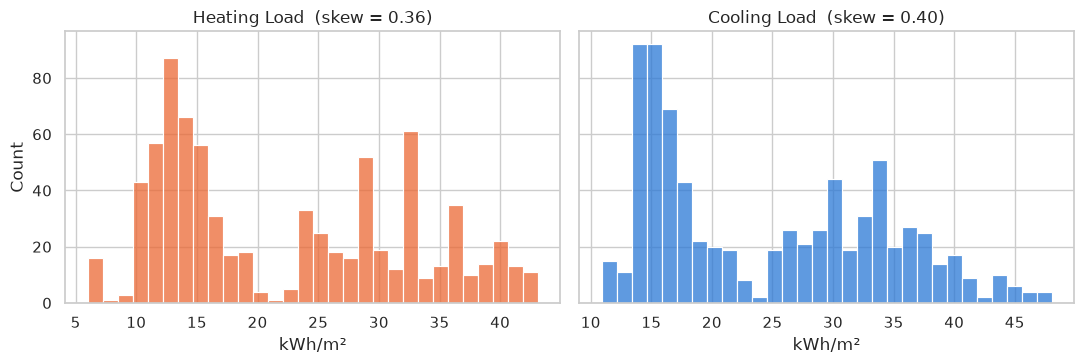

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, t, col in zip(axes, TARGETS, [HEAT, COOL]):
    sns.histplot(df[t], bins=30, color=col, ax=ax, edgecolor="white")
    ax.set_title(f"{t.replace('_', ' ')}  (skew = {df[t].skew():.2f})")
    ax.set_xlabel("kWh/m²")
plt.tight_layout(); plt.show()

From the ***Histogram*** we see that the distributions are **Right Skewed** but the skew value for the **Heating Load** is **0.36** and for **Cooling Load** it is **0.40** which means the data is roughly balanced and no need for the transformation.

What do we get from the ***Histograms***:
1. The data divides the buildings into two groups on both **Heating Load** and **Cooling Load**.

Now for each **Feature** we would need to know how often does each value appears and if there is any abnormality(any rare value) in the values.

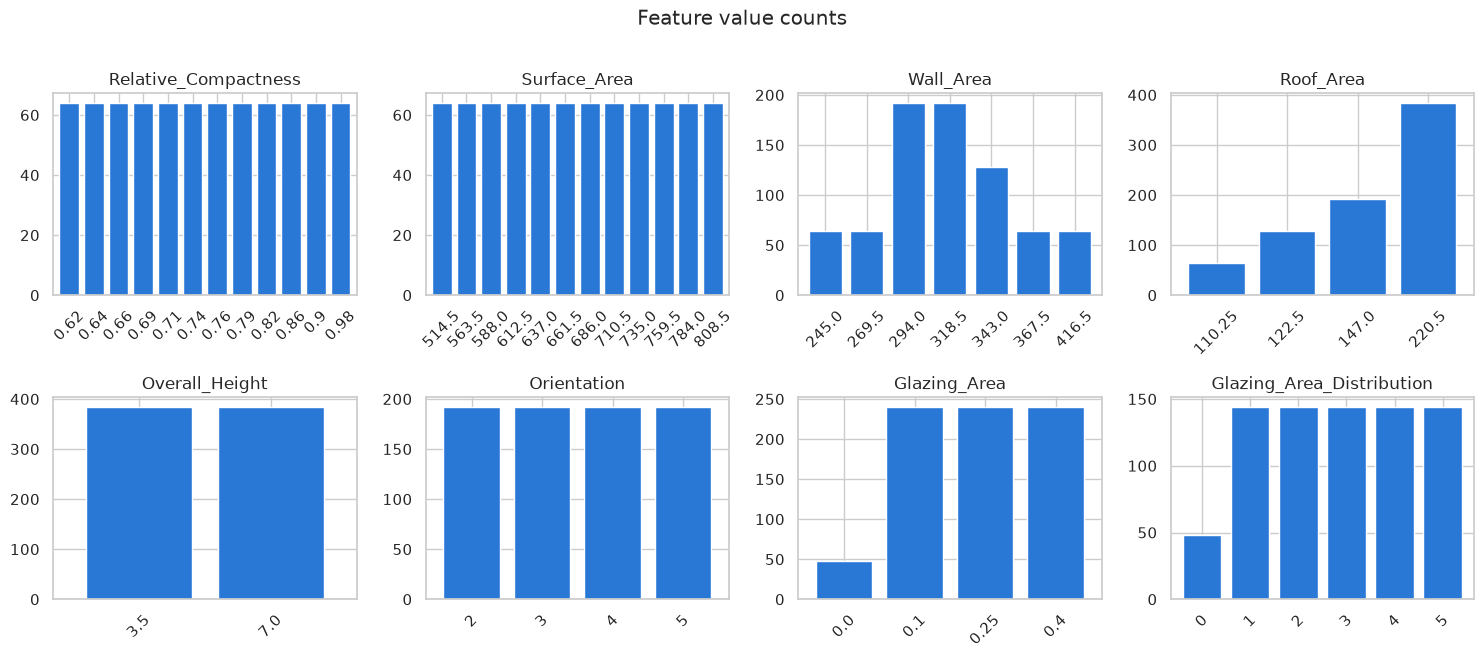

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, f in zip(axes.flat, FEATURES):
    df[f].value_counts().sort_index().plot.bar(ax=ax, color=BLUE, edgecolor="white", width=0.8)
    ax.set_title(f); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=45)
plt.suptitle("Feature value counts", y=1.01); plt.tight_layout(); plt.show()

The ***Bar Chart*** shows how often does each value appear and seeing from the bar charts, each value appear often equally eg. **384 builings** for both **3.5m** and **7m** height, **192 buildings** per orientation. This basically tells us that the data is balanced.

Although there is one exception for the ***Glazing_Area*** and the ***Glazing_Area_Distribution*** charts. **48 buildings** have **Glazing_Area=0** and the same **48 buildings** have **Glaze_Area_Distribution=0**, so that value simply repeats the fact that there are **no windows**.

### 4. Outliers

Now that we have the info of the dataset, no missing or duplicates and we know data distribution is balanced, we will be finding the plausible outliers.

To find the Outliers we will use **2 methods**:
1. The IQR (Inter Quartile Range) Method.
2. Identical Twin Check - uses the IQR method but with grouping the data

The IQR method basically have **5 Steps** but pandas does the most of us, we just need to input some formulas and the ranges (0.25, 0.75). 

1. **0.25** is the Lower Fence.
2. **0.75** is the Upper Fence.
3. We first find the medians **q1 and q2** of both lower and upper half.
4. Then calculate the IQR by **q3-q1**.
5. Then build fences i.e. allow **1.5 * IQR** for the extra room for each fence.
6. Then calculate the lower fence (**q1 - 1.5 * iqr**) and upper fence (**q3 + 1.5 * iqr**).

Then we see that every value should be withing the range of lower fence and upper fence. Anything outside that range is considered as **Outlier**.


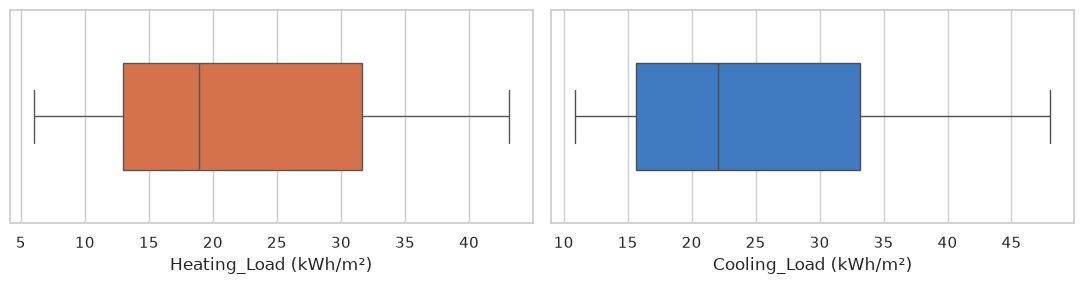

,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution,Heating_Load,Cooling_Load
IQR outliers,0,0,0,0,0,0,0,0,0,0


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
for ax, t, col in zip(axes, TARGETS, [HEAT, COOL]):
    sns.boxplot(x=df[t], color=col, ax=ax, width=0.5); ax.set_xlabel(f"{t} (kWh/m²)")
plt.tight_layout(); plt.show()

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

df.apply(iqr_outliers).rename("IQR outliers").to_frame().T

In our plot there are no dots. The whiskers simply end at the smallest and largest buildings. That’s the **IQR result**. This means that there are no outliers but for surety we would do the **Identical Twin Check**.

So the **IQR Method** tells us that there are no outliers and the values looks normal but the **Identical Twin Check Method** tells us that no matter if the values look good overall, they still can be **odd values**. 

in this dataset, every design (same shape, same windows) was simulated 4 times, once facing each direction ***(North, East, South, West)***. Turning a building around barely changes its heating, so those 4 twins should have almost the same heating load.

Now, we will be checking this and to do this we have **4 Steps**:

1. Group the twins: buildings that are identical except for orientation.
2. Find each group’s middle value (median).
3. Measure how far each building is from its group’s median.
4. Sort by that distance: the top of the list is the most suspicious.

In [8]:
design_cols = [c for c in FEATURES if c != "Orientation"]
dev = df[["Heating_Load"]].copy()
dev["group_median"] = df.groupby(design_cols)["Heating_Load"].transform("median")
dev["abs_deviation"] = (df["Heating_Load"] - dev["group_median"]).abs()
pd.concat([df[design_cols + ["Orientation"]], dev], axis=1).sort_values("abs_deviation", ascending=False).head(5).round(2)

,Relative_Compactness,Surface_Area,Wall_Area,Roof_Area,Overall_Height,Glazing_Area,Glazing_Area_Distribution,Orientation,Heating_Load,group_median,abs_deviation
271,0.71,710.5,269.5,220.5,3.5,0.1,5,5,13.69,10.74,2.95
572,0.62,808.5,367.5,220.5,3.5,0.4,1,2,15.09,17.14,2.05
259,0.79,637.0,343.0,147.0,7.0,0.1,5,5,35.48,36.74,1.26
11,0.86,588.0,294.0,147.0,7.0,0.0,0,5,18.31,19.42,1.11
7,0.90,563.5,318.5,122.5,7.0,0.0,0,5,19.68,20.78,1.09


Now, if we look at the table, we need to look at **2 cols** specifically:
1. ```Heating_Load```
2. ```group_median```

For the **last 3** groups, there is not much difference between their heating load and group median values but for the **first 2** groups, the ```abs_deviation``` is big, which means that these two buildings can be considered as outliers.

Since, the gap in these values is minimal, and such small gap won't affect the model so we can **keep them**. 

### 5. Relationships between features and targets

So far in each step we have looked into each feature on it's own. Now, we need to see how each feature affect the ```energy_loads```.

We do this in **3 steps**:
1. The Correlation heatmap - numerically we see how each feature affects the energy load. **+1** means both go up together, **−1** means one goes up while the other goes down, **0** means no link.
2. Check whether a number is lying or not?
3. See what each relationship looks like.

First, we will be making the **Correlation Heatmap** and then analyzing it to see what features affect the energy load the most and the least.

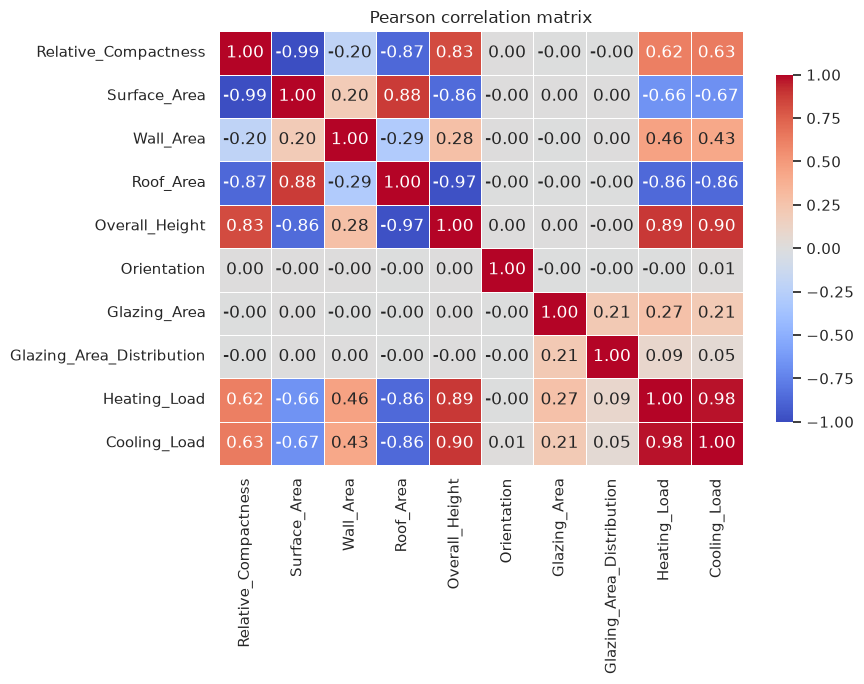

In [9]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Pearson correlation matrix"); plt.tight_layout(); plt.show()

Correlation summarises each relationship in one number and can **hide** its shape. Since every feature takes only a few values, we plot the average heating and cooling load at each feature value (with 95% confidence intervals) to see whether each effect is a straight trend, a jump, or flat.

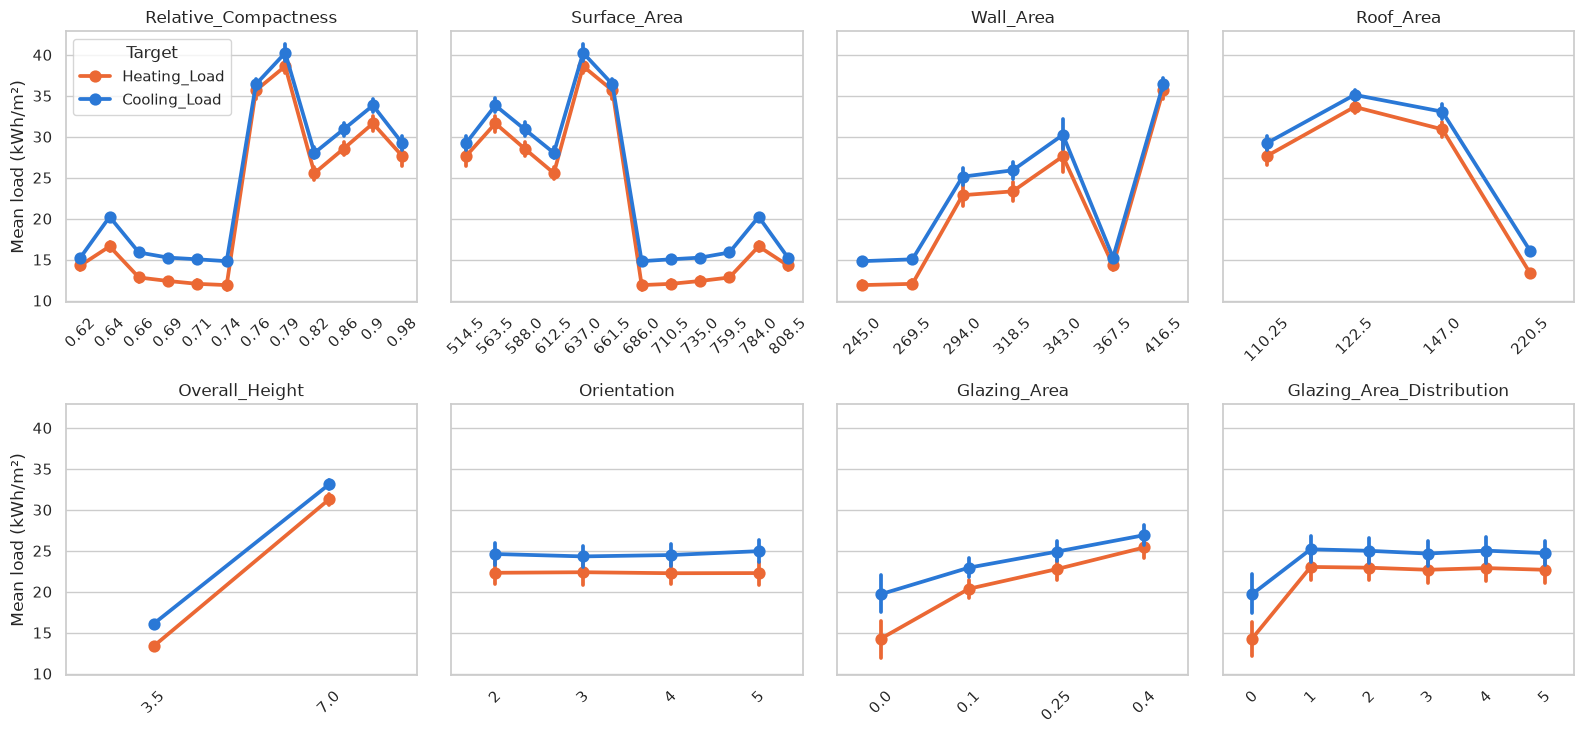

In [10]:
long = df.melt(id_vars=FEATURES, value_vars=TARGETS, var_name="Target", value_name="Load")
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5), sharey=True)
for ax, f in zip(axes.flat, FEATURES):
    sns.pointplot(data=long, x=f, y="Load", hue="Target", palette=[HEAT, COOL],
                  errorbar=("ci", 95), markers="o", linestyles="-", ax=ax, legend=(f == FEATURES[0]))
    ax.set_title(f); ax.set_xlabel(""); ax.set_ylabel("Mean load (kWh/m²)"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

Height has the largest effect: 7 m buildings need more than twice the energy of 3.5 m buildings. Higher glazing area raises the energy load gradually. Orientation shows no effect on average, and glazing distribution only matters as “no windows vs windows”. Several relationships are jumps or zig-zags rather than straight lines, telling us that a **non-linear model** would be a good fit.

```Relative_Compactness``` correlates positively with heating load **(+0.62)**, although physics says *a more compact building should lose less heat* - high relative compactness then low heating load. We split the buildings by height to check whether height is hiding behind this result.

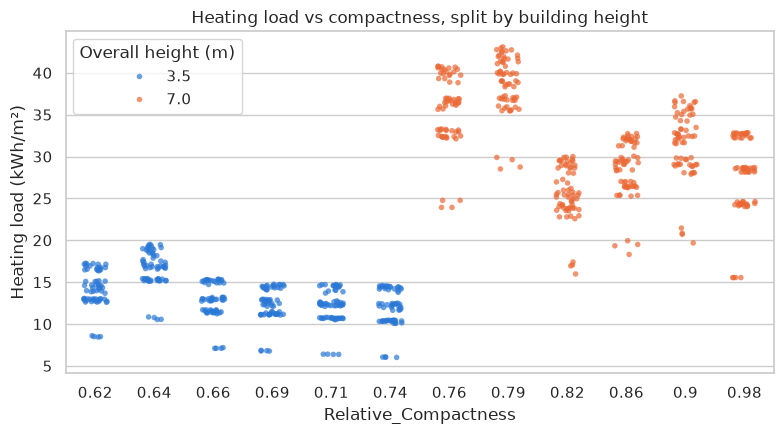

Correlation (Relative_Compactness vs Heating_Load)
  overall       : 0.62
  height = 3.5 m : -0.48
  height = 7.0 m : -0.44


In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.stripplot(data=df, x="Relative_Compactness", y="Heating_Load", hue="Overall_Height",
              palette=[BLUE, HEAT], jitter=0.2, size=4, alpha=0.7, ax=ax)
ax.set_ylabel("Heating load (kWh/m²)"); ax.legend(title="Overall height (m)")
ax.set_title("Heating load vs compactness, split by building height")
plt.tight_layout(); plt.show()

print("Correlation (Relative_Compactness vs Heating_Load)")
print("  overall       :", round(df["Relative_Compactness"].corr(df["Heating_Load"]), 2))
for h, d in df.groupby("Overall_Height"):
    print(f"  height = {h} m :", round(d["Relative_Compactness"].corr(d["Heating_Load"]), 2))

From the strip plot above, all **compact shapes (0.76–0.98)** are **7 m tall**, and all **less compact shapes (0.62–0.74)** are **3.5 m tall**. 

Comparing between the two groups, the tall, compact buildings use more energy because they are tall and this creates the *misleading positive correlation (+0.62)*. 

Comparing within each height group, more compact buildings need less heating **(−0.48 for 3.5 m, −0.44 for 7 m)**. 

This reversal is an example of **Simpson’s paradox**. Hence, **correlation** alone is therefore not used to judge or remove features.

Correlation said ```Orientation``` does nothing **(0.00)**. We need to see if that's really true?

We compare the **4 twin buildings** of each design (identical except for orientation) and calculate how much the load changes between them *(largest minus smallest)*. The results are averaged for each building shape.

In [12]:
design_cols = [c for c in FEATURES if c != "Orientation"]
orient_range = (df.groupby(design_cols)[TARGETS].agg(lambda s: s.max() - s.min())
                  .groupby("Relative_Compactness").mean().round(2))
orient_range.columns = ["Heating range from orientation", "Cooling range from orientation"]
orient_range

,Heating range from orientation,Cooling range from orientation
Relative_Compactness,,
0.62,0.39,0.45
0.64,0.27,0.39
0.66,0.17,0.43
0.69,0.23,0.61
0.71,0.37,0.66
0.74,0.21,0.51
0.76,0.83,0.95
0.79,1.48,8.86
0.82,1.23,3.77


Turning a building changes its heating load by less than 1.5 for every shape, so orientation barely affects heating. 

For cooling, the change is also small **(under 1)** for most shapes, but for **four tall shapes** *(compactness 0.79, 0.82, 0.86 and 0.90)* orientation alone changes the cooling load **above 1.5** *(8.86,3.77, 5.97, 4.90)*. 

These effects cancel out on average, which is why the correlation is 0. Orientation therefore affects cooling through an interaction with building shape, so it is kept as a feature.

### 6. Multicollinearity

Uptil now, we have seen the relationship between the feature and the targets. Now, we need to see how each feature affects the other features i.e. **Do some features repeat the same information?**

Feature cols which carry the same information are said to have **Multicolinearity**.

There are two types of it:
1. Exact copy.
2. Near copies.

The exact copy here will be the **Surface Area**. If we look closely, we will notice that **Wall_Area + 2 * Roof_Area = Surface_Area**, so if we know the **Wall_Area** and **Roof_Area** we know the **Surface_Area**, hence **Surface_Area's** standalone col gives no additional or unique info.

Similarly, some features are not the exact copies but they are near copies, and we find this by **Variance inflation factor (VIF)**. For VIF, we predict each feature from all other features:
1. If other features predict that feature badly it means that feature tells a unique information.
2. If other features predicts it almost perfectly, it means that feature is a unique copy.

*A VIF value above **10** decides if a feature is unique or exact copy.*

In [13]:
def vif_table(data, cols):
    out = {}
    for c in cols:
        others = [o for o in cols if o != c]
        r2 = LinearRegression().fit(data[others], data[c]).score(data[others], data[c])
        out[c] = np.inf if r2 >= 1 - 1e-12 else 1 / (1 - r2)
    return pd.Series(out, name="VIF").round(1)

print("Surface_Area == Wall_Area + 2 * Roof_Area for every row:",
      np.allclose(df["Surface_Area"], df["Wall_Area"] + 2 * df["Roof_Area"]))

pd.concat([vif_table(df, FEATURES).rename("VIF (all 8)"),
           vif_table(df, [f for f in FEATURES if f != "Surface_Area"]).rename("VIF (without Surface_Area)")], axis=1)

Surface_Area == Wall_Area + 2 * Roof_Area for every row: True


,VIF (all 8),VIF (without Surface_Area)
Relative_Compactness,105.5,105.5
Surface_Area,inf,NaN
Wall_Area,inf,27.7
Roof_Area,inf,211.9
Overall_Height,31.2,31.2
Orientation,1.0,1.0
Glazing_Area,1.0,1.0
Glazing_Area_Distribution,1.0,1.0


Surface_Area, Wall_Area, Roof_Area have an infinite VIF. Surface_Area adds no new information and is resultantly dropped. 

After removing it, **Roof_Area (212)**, **Relative_Compactness (105)**, **Overall_Height (31)** and **Wall_Area (28)** still have high VIF values because all four are determined by the building’s shape. The dataset contains only 12 shapes, so knowing one of these values largely tells you the other three

For example, **Roof_Area** and **Overall_Height** correlate at **−0.97**: all short buildings have the large roof. However, they are not exact copies, since the tall buildings come in three different roof sizes, so each feature still carries some unique information. 

**Overall_Height** is also the strongest and most interpretable driver of energy use, so it must be kept. 

Instead of dropping more features manually, **Ridge** and **Lasso regression** will be used in **Part 2**: 
- Ridge shares the weight between correlated features
- Lasso can set a redundant feature’s weight to **zero** by itself. 

Orientation and the two glazing features have a VIF of 1.0 i.e. they are fully independent of the other features.

### 7. Feature selection & transformation

The following decisions are made after the whole analysis:
- **Drop `Surface_Area`**: it's an exact linear combination of `Wall_Area` and `Roof_Area` (infinite VIF), so it adds no information.
- **Keep `Roof_Area` and `Relative_Compactness` despite high VIF**: they are not *exact* duplicates, and Part 2 uses Ridge/Lasso, which are designed to handle correlated features.
- **Keep `Orientation`**: it has no average effect, but it changes cooling load by several kWh/m² for some shapes.
- **One-hot encode `Orientation` and `Glazing_Area_Distribution`**: they're categories, not quantities.
- **No target transformation**: skew is about 0.4 which means most of the data is balanced so need for transformation.
- **Scaling** (StandardScaler) will be done *after* the train/test split in Part 2, fitting on the training set only, to avoid data leakage.

Now, we prepare the inputs for the model. **X (inputs)**, **Y (the targets)**. The target values will be in the seperate table because the model must learn to predict them from the input values only, if the target values stayed in X, the model would see the answers. We will remove the the surface area col from the features and convert **Orientation** and **Glazing_Area_Distribution** into *yes/no (one-hot)* cols so the model treat them as categories not amounts.

In [14]:
X = df.drop(columns=TARGETS + ["Surface_Area"])
X = pd.get_dummies(X, columns=["Orientation", "Glazing_Area_Distribution"], drop_first=True, dtype=int)
y = df[TARGETS]
print("X:", X.shape, "| y:", y.shape)
X.head()

X: (768, 13) | y: (768, 2)


,Relative_Compactness,Wall_Area,Roof_Area,Overall_Height,Glazing_Area,Orientation_3,Orientation_4,Orientation_5,Glazing_Area_Distribution_1,Glazing_Area_Distribution_2,Glazing_Area_Distribution_3,Glazing_Area_Distribution_4,Glazing_Area_Distribution_5
0,0.98,294.0,110.25,7.0,0.0,0,0,0,0,0,0,0,0
1,0.98,294.0,110.25,7.0,0.0,1,0,0,0,0,0,0,0
2,0.98,294.0,110.25,7.0,0.0,0,1,0,0,0,0,0,0
3,0.98,294.0,110.25,7.0,0.0,0,0,1,0,0,0,0,0
4,0.90,318.5,122.50,7.0,0.0,0,0,0,0,0,0,0,0


The final feature matrix:
- X has 768 rows and 13 columns
- Target matrix y has 768 rows and 2 columns (Heating_Load and Cooling_Load). 

X contains the **5 numeric features**:
1. Relative_Compactness
2. Wall_Area
3. Roof_Area
4. Overall_Height
5. Glazing_Area

with **Surface_Area removed**. **Orientation** was converted into **3 yes/no** columns (East, South, West) and **Glazing_Area_Distribution** into 5 (uniform, North, East, South, West). The first category of each (North, and “no windows”) is represented by all zeros, which avoids a duplicate column.

## Part 2 - Model Selection & Evaluation

Part 1 was about understanding the data whereas Part 2 is about using it i.e. build models that predict buildings heating and cooling load from it's design and test how good the results are. 

We will be doing it in **6** steps:
1. Train/Test split.
2. Scaling
3. Train the 3 models.
4. Evaluate
5. Predict
6. Recommend

### 1. Train/Test split

We usually get **4** pieces from this train/test split:
1. X_train - inputs of training buildings
2. X_test - inputs of test buildings
3. y_train - answers of the training building
4. y_test - answers of the test buildings

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((614, 13), (154, 13), (614, 2), (154, 2))

### 2. Scaling

Our features use very different ranges and when we will use Ridge & Lasso models, they work by penalising big weights and weight's size depend on the features units. Hence, features with big units will get small weights and dodge penalty and features with small units will get unfairly punished. 

In **Part 3** we will be using **Neural Networks** and neural networks works faster and reliable when the inputs are on similar scale. 

The most **important rule** for scaling is that the **Scaler** function learn each cols mean and std deviation from the **training set** only and then apply to both sets. If it learns from the test set, it would cause **Data Leakage**.

The models will be trained on **Scaled Training sets** and the models will predict on **Scaled Testing sets**.

In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.set_output(transform="pandas")

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled.head()

,Relative_Compactness,Wall_Area,Roof_Area,Overall_Height,Glazing_Area,Orientation_3,Orientation_4,Orientation_5,Glazing_Area_Distribution_1,Glazing_Area_Distribution_2,Glazing_Area_Distribution_3,Glazing_Area_Distribution_4,Glazing_Area_Distribution_5
60,0.553671,-0.007372,-0.679048,1.016421,-1.010300,-0.591143,-0.581112,-0.576097,2.094270,-0.480063,-0.492864,-0.467177,-0.480063
618,-1.155118,0.558439,0.957063,-0.983844,1.227790,-0.591143,1.720840,-0.576097,-0.477493,2.083058,-0.492864,-0.467177,-0.480063
346,0.933402,-0.573184,-0.679048,1.016421,0.108745,-0.591143,1.720840,-0.576097,-0.477493,2.083058,-0.492864,-0.467177,-0.480063
294,1.313133,-0.007372,-1.224418,1.016421,0.108745,-0.591143,1.720840,-0.576097,2.094270,-0.480063,-0.492864,-0.467177,-0.480063
231,-0.965252,-0.007372,0.957063,-0.983844,-1.010300,-0.591143,-0.581112,1.735820,-0.477493,-0.480063,-0.492864,2.140518,-0.480063


After scaling, every training column has a mean of 0 and a standard deviation of 1, so all features are now on the same scale. 

The test set means are close to 0 but not exactly 0, which confirms it was scaled using the training set’s statistics rather than its own.

## 3. Train 3 models 

Now, that our data is ready, we will be initiating the training phase, where the models will train on the **scaled training data**.

We will be using:
1. Linear Regression
2. Ridge
3. Lasso

Liner Regression will be our **Baseline Model**, we will comapare the results of the other two with this.

In [17]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso

lr = LinearRegression()
ridge = Ridge(alpha=1.0)
lasso = Lasso(alpha=0.1)
lr.fit(X_train_scaled, y_train)
ridge.fit(X_train_scaled, y_train)
lasso.fit(X_train_scaled, y_train);

In [18]:
pred_lr=lr.predict(X_test_scaled[:5])
pred_ridge=ridge.predict(X_test_scaled[:5])
pred_lasso=lasso.predict(X_test_scaled[:5])

heating = pd.DataFrame({
    "Actual Heating Load": y_test["Heating_Load"][:5].values,
    "Linear Regression": pred_lr[:, 0],
    "Ridge Regression": pred_ridge[:, 0],
    "Lasso Regression": pred_lasso[:, 0],
}, index=y_test.index[:5])
heating.round(2)

cooling = pd.DataFrame({
    "Actual Cooling Load": y_test["Cooling_Load"][:5].values,
    "Linear Regression": pred_lr[:,1],
    "Ridge Regression": pred_ridge[:,1],
    "Lasso Regression": pred_lasso[:,1],
}, index=y_test.index[:5])
cooling.round(2)

display(heating, cooling)

,Actual Heating Load,Linear Regression,Ridge Regression,Lasso Regression
668,16.47,18.675229,18.977076,19.821940
324,13.17,14.752431,14.719590,14.334891
624,32.82,31.136477,31.368959,32.658174
690,41.32,35.204890,35.148192,34.677492
473,16.69,14.965627,15.079350,15.216155


,Actual Cooling Load,Linear Regression,Ridge Regression,Lasso Regression
668,16.90,19.965530,20.307604,20.880584
324,16.39,17.313723,17.279017,16.869005
624,32.78,32.211354,32.464939,33.465648
690,46.23,36.379590,36.319513,35.995841
473,19.76,16.917637,17.052393,17.531161


All three models were trained on the **614 training buildings**. 

On the first **5 test buildings**, the three models give very similar predictions, and most are within about 1–3 kWh/m² of the actual values. 

The **Building 690** is a clear exception: its heating is underestimated by about **6** and its cooling by about **10** kWh/m². This building has shape **0.79**, where orientation alone changes cooling by about **9** kWh/m² *(see 1.5)*. Linear models give orientation almost no weight, so they cannot capture this interaction.

## 4. Evaluate

In the previous section, we only checked the predicted values with the 5 test values. Now, we need to compare for our entire testing set and see how each model performed and which one was the best.

For this we will be using 3 techniques:
1. MSE (Mean Squared Error)
2. RMSE (Root Mean Squared Error)
3. R²

In [19]:
from sklearn.metrics import mean_squared_error, r2_score

models = {"Linear Regression": lr, "Ridge Regression": ridge, "Lasso Regression": lasso}
results = []
for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    results.append({
        "Model": name,
        "MSE (Heating)": mean_squared_error(y_test["Heating_Load"], y_pred[:, 0]),
        "R² (Heating)": r2_score(y_test["Heating_Load"], y_pred[:, 0]),
        "MSE (Cooling)": mean_squared_error(y_test["Cooling_Load"], y_pred[:, 1]),
        "R² (Cooling)": r2_score(y_test["Cooling_Load"], y_pred[:, 1]),
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

best_row = results_df["R² (Heating)"].idxmax()
best_model = results_df.loc[best_row, "Model"]
best_r2 = results_df.loc[best_row, "R² (Heating)"]
print(f"Best model for Heating Load: {best_model} with R² = {best_r2:.4f}")

best_row_cooling = results_df["R² (Cooling)"].idxmax()
best_model_cooling = results_df.loc[best_row_cooling, "Model"]
best_r2_cooling = results_df.loc[best_row_cooling, "R² (Cooling)"]
print(f"Best model for Cooling Load: {best_model_cooling} with R² = {best_r2_cooling:.4f}")

,Model,MSE (Heating),R² (Heating),MSE (Cooling),R² (Cooling)
0,Linear Regression,8.2501,0.9208,9.7329,0.8950
1,Ridge Regression,8.3514,0.9199,9.7943,0.8943
2,Lasso Regression,10.1864,0.9023,10.7958,0.8835


Best model for Heating Load: Linear Regression with R² = 0.9208
Best model for Cooling Load: Linear Regression with R² = 0.8950


**Linear Regression** performs **best** on both targets: R² = 0.921 for heating (MSE 8.25, i.e. a typical error of about 2.9 kWh/m²) and R² = 0.895 for cooling (MSE 9.73, about 3.1 kWh/m²).

**Ridge** is almost identical, since a small penalty **(alpha = 1)** changes the predictions very little; the overlapping features from 1.6 mainly affect the weights, not the predictions. 
 
**Lasso** scores slightly **lower** (R² = 0.902 and 0.883) because **alpha = 0.1** removed some useful information along with the redundant features. 

All models predict **cooling less accurately** than heating, which matches the hidden orientation effect on cooling found in *Part 1 - 5th section*, an interaction that **straight-line models cannot capture**.

## 5. Predict

In the **Evaluation** step, each model got **MSE** and **R²** values, but it didn't tell us that where the model got wrong: on small buildings? on tall buildings?

So, in this section, we will see our best performing model **Linear Regression** deeply and at the end make a prediction on a new building which is refered as *future observations* in assignment doc.

We will be performing 3 steps:

1. Predicted vs Original 
2. Where did the major mistakes happen
3. Prediction for a new building

### 1. Predicted vs Original

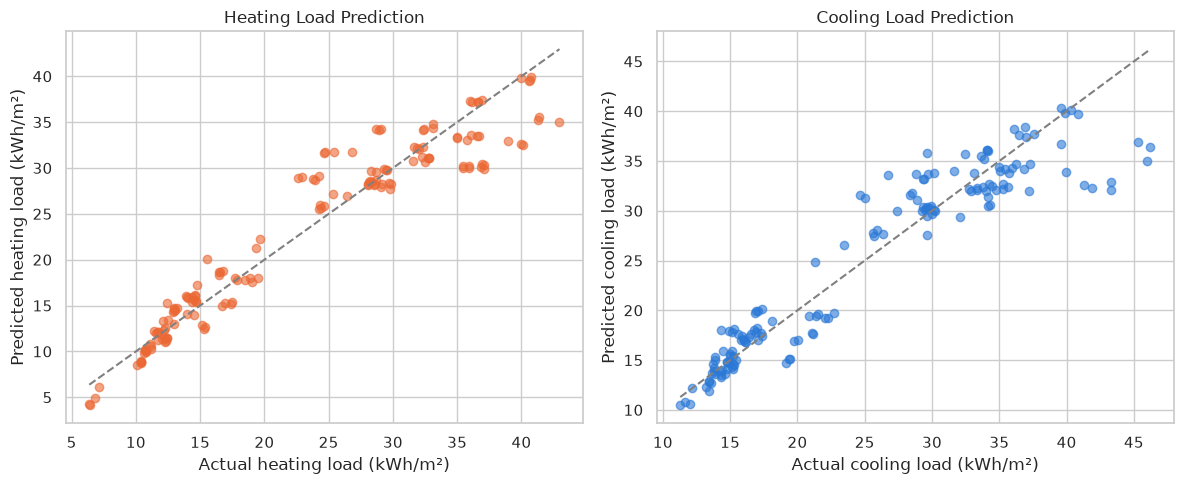

In [20]:
predictions = lr.predict(X_test_scaled)
actual_heat = y_test["Heating_Load"]
predicted_heat = predictions[:, 0]

actual_cool = y_test["Cooling_Load"]
predicted_cool = predictions[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(actual_heat, predicted_heat, alpha=0.6, color=HEAT)
axes[0].plot([actual_heat.min(), actual_heat.max()],
             [actual_heat.min(), actual_heat.max()], "--", color="gray")
axes[0].set_xlabel("Actual heating load (kWh/m²)")
axes[0].set_ylabel("Predicted heating load (kWh/m²)")
axes[0].set_title("Heating Load Prediction")

axes[1].scatter(actual_cool, predicted_cool, alpha=0.6, color=COOL)
axes[1].plot([actual_cool.min(), actual_cool.max()],
             [actual_cool.min(), actual_cool.max()], "--", color="gray")
axes[1].set_xlabel("Actual cooling load (kWh/m²)")
axes[1].set_ylabel("Predicted cooling load (kWh/m²)")
axes[1].set_title("Cooling Load Prediction")

plt.tight_layout(); plt.show()

The model is acting **pretty good** for **small buildings** as we can see in the **lower-left** corner but the predictions for **tall buildings** i.e. **top-right** are a **spread-out** and the buildings with the **highest loads** are **underpredicted**. 

One of the main reason is that the straight-line models can't catch the jump or zig-zag behaviour of the data.

### 2. Where did the major mistakes happen

Now that we know model predictions for the **tall buildings** are spread out, now we need to prove it through numbers.

In [21]:
errors_heat = pd.DataFrame({"actual": actual_heat, "predicted": predicted_heat})

errors_heat["abs_error"] = (errors_heat["actual"] - errors_heat["predicted"]).round(2)
errors_heat["height"] = X_test["Overall_Height"].values
errors_heat["shape"] = X_test["Relative_Compactness"].values

display(errors_heat.groupby(["height", "shape"])["abs_error"].mean().round(2))
display(errors_heat.sort_values("abs_error", ascending=False).head(5))

#----------------------------------------------------------------------------------#

errors_cool = pd.DataFrame({"actual": actual_cool, "predicted": predicted_cool})

errors_cool["abs_error"] = (errors_cool["actual"] - errors_cool["predicted"]).round(2)
errors_cool["height"] = X_test["Overall_Height"].values
errors_cool["shape"] = X_test["Relative_Compactness"].values

display(errors_cool.groupby(["height", "shape"])["abs_error"].mean().round(2))
display(errors_cool.sort_values("abs_error", ascending=False).head(5))

height  shape
3.5     0.62    -1.69
        0.64     1.52
        0.66    -1.09
        0.69    -0.31
        0.71     0.17
        0.74     1.00
7.0     0.76    -0.89
        0.79     6.47
        0.82    -5.79
        0.86    -0.73
        0.90     1.34
        0.98    -0.26
Name: abs_error, dtype: float64

,actual,predicted,abs_error,height,shape
691,42.96,35.039731,7.92,7.0,0.79
451,40.12,32.455606,7.66,7.0,0.79
448,40.00,32.667811,7.33,7.0,0.79
211,37.10,29.871482,7.23,7.0,0.79
208,36.86,30.083687,6.78,7.0,0.79


height  shape
3.5     0.62    -2.79
        0.64     3.06
        0.66    -0.91
        0.69    -0.11
        0.71    -0.05
        0.74     0.47
7.0     0.76    -1.16
        0.79     6.10
        0.82    -4.42
        0.86     0.06
        0.90     1.52
        0.98    -0.50
Name: abs_error, dtype: float64

,actual,predicted,abs_error,height,shape
209,43.30,32.056217,11.24,7.0,0.79
355,45.97,34.967290,11.00,7.0,0.79
67,43.33,32.842887,10.49,7.0,0.79
690,46.23,36.379590,9.85,7.0,0.79
210,41.86,32.323923,9.54,7.0,0.79


Errors are small for short buildings. Among tall buildings, most errors come from shapes **0.79** and **0.82**. 

The signed errors show that every shape of **0.79** building is ***underpredicted*** (mean error **+6.47** heating, up to 11 kWh/m² for cooling), while every shape of **0.82** building is **overpredicted** (mean error **−5.79** heating). 

The linear model treats all tall buildings as average and cannot apply a separate rule per shape.

### 3. Prediction for a new Building

We define a new building with **30%** glazing (a value not in the dataset), using the of shape (Relative Compactness) of **0.86**.

In [22]:
new_building = pd.DataFrame([{
    "Relative_Compactness": 0.86,
    "Wall_Area": 294,
    "Roof_Area": 147,
    "Overall_Height": 7,
    "Orientation": 4,
    "Glazing_Area": 0.30,
    "Glazing_Area_Distribution": 3,
}])

display(new_building)

,Relative_Compactness,Wall_Area,Roof_Area,Overall_Height,Orientation,Glazing_Area,Glazing_Area_Distribution
0,0.86,294,147,7,4,0.3,3


---

Now that we have the new data point, we **one-hot encode** the new building and align its columns with the training set, so it also has the same **13 columns** in the same order.

In [23]:
new_X = pd.get_dummies(new_building, columns=["Orientation", "Glazing_Area_Distribution"], dtype=int)
new_X = new_X.reindex(columns=X_train.columns, fill_value=0)

display(new_X.T)

,0
Relative_Compactness,0.86
Wall_Area,294.00
Roof_Area,147.00
Overall_Height,7.00
Glazing_Area,0.30
Orientation_3,0.00
Orientation_4,1.00
Orientation_5,0.00
Glazing_Area_Distribution_1,0.00
Glazing_Area_Distribution_2,0.00


---

Now, we scale the new building with the scaler fitted on the training set (transform only, no re-fitting).

In [24]:
new_scaled = scaler.transform(new_X)
display(new_scaled.T)

,0
Relative_Compactness,0.933402
Wall_Area,-0.573184
Roof_Area,-0.679048
Overall_Height,1.016421
Glazing_Area,0.481760
Orientation_3,-0.591143
Orientation_4,1.720840
Orientation_5,-0.576097
Glazing_Area_Distribution_1,-0.477493
Glazing_Area_Distribution_2,-0.480063


Now that the data point is fully aligned with our training data points, we predict the heating and cooling load of the new building with the Linear Regression model.

In [25]:
new_pred = lr.predict(new_scaled)

print(f"Predicted Heating Load: {new_pred[0, 0]:.2f} kWh/m²")
print(f"Predicted Cooling Load: {new_pred[0, 1]:.2f} kWh/m²")

Predicted Heating Load: 30.61 kWh/m²
Predicted Cooling Load: 32.28 kWh/m²


---

Now we need to check if the predictions made are valid or wrong, so to check that, we compare it with the same building at **25%** and **40%** glazing from the dataset because our new data point had **30%** glazing and it sits between **25%** and **40%**.

In [26]:
same_building = df[(df["Relative_Compactness"] == 0.86) &
                   (df["Orientation"] == 4) &
                   (df["Glazing_Area_Distribution"] == 3)]

display(same_building[["Glazing_Area", "Heating_Load", "Cooling_Load"]])

,Glazing_Area,Heating_Load,Cooling_Load
154,0.10,26.89,25.90
394,0.25,29.43,28.38
634,0.40,32.05,30.11


The model predicts **30.61 (heating)** and **32.28 kWh/m² (cooling)** for a new building with **30%** glazing. 

The **heating prediction** is **plausible**, lying between the same building’s values at 25% and 40% glazing (29.43 and 32.05). 

The **cooling prediction** is **not** i.e. it is higher than both neighbours (28.38 and 30.11), showing that the linear model can not capture the **shape - orientation** interaction that affects cooling.

## 4. Recommendation

In [27]:
coef_heat = pd.DataFrame({
    "Linear": lr.coef_[0],
    "Ridge":  ridge.coef_[0],
    "Lasso":  lasso.coef_[0],
}, index=X_train_scaled.columns)

display(coef_heat.round(2))

coef_cool = pd.DataFrame({
    "Linear": lr.coef_[1],
    "Ridge":  ridge.coef_[1],
    "Lasso":  lasso.coef_[1],
}, index=X_train_scaled.columns)

display(coef_cool.round(2))

,Linear,Ridge,Lasso
Relative_Compactness,-6.58,-4.92,-0.00
Wall_Area,-1.02,-0.19,2.15
Roof_Area,-7.64,-5.47,-0.00
Overall_Height,7.23,7.73,8.24
Glazing_Area,2.31,2.32,2.66
Orientation_3,-0.05,-0.05,-0.00
Orientation_4,-0.02,-0.02,0.00
Orientation_5,-0.09,-0.09,-0.00
Glazing_Area_Distribution_1,1.60,1.56,0.13
Glazing_Area_Distribution_2,1.65,1.61,0.21


,Linear,Ridge,Lasso
Relative_Compactness,-7.48,-5.57,-0.47
Wall_Area,-1.89,-0.94,1.49
Roof_Area,-8.29,-5.77,-0.00
Overall_Height,7.13,7.73,8.35
Glazing_Area,1.81,1.82,1.92
Orientation_3,-0.26,-0.26,-0.12
Orientation_4,-0.14,-0.14,-0.00
Orientation_5,0.02,0.02,0.02
Glazing_Area_Distribution_1,0.67,0.65,0.00
Glazing_Area_Distribution_2,0.71,0.70,0.05


Design (to reduce energy use)

1. **Keep buildings low.** Height has the largest effect in all models (Lasso weight ≈ +8). **3.5 m** buildings need less than half the heating of 7 m buildings **(≈13 vs 31 kWh/m²)**.
2. **Limit window area.** Average heating rises from **≈14 (no windows)** to **≈25 kWh/m² (40% glazing)**.
3. **Reduce wall area.** More wall area increases both heating and cooling loads **(Lasso weight ≈ +2)**.
4. **Orientation and window placement** have little effect on average, but orientation can change **cooling** by up to **≈9 kWh/m²** for some tall shapes (0.79, 0.82, 0.86, 0.90), so it should be checked case by case.

Using the model for future buildings:

1. Linear Regression is reliable for **heating** (R² = 0.92, typical error ≈ 2.9 kWh/m²).
2. **Cooling** predictions are less reliable (R² = 0.90), especially for shapes 0.79 and 0.82, where errors reach ≈11 kWh/m².
3. Use the model only **within the range of the data** (height 3.5 or 7 m, glazing 0–40%). Predictions outside this range are extrapolations and should not be trusted.

## Part 3: Neural Network Regression

The linear models in Part 2 can only fit straight-line relationships so they struggled where the data was represented as jumps or zig zags (e.g. shapes 0.79 and 0.82, and the orientation effect on cooling). 

In this part, we will build a neural network, which can learn these non-linear patterns, and compare it with the Part 2 models on the same test set. We also track every experiment with MLflow and tune the network's hyperparameters with GridSearchCV.

**Steps:**

1. Setup: install TensorFlow, MLflow and scikeras
2. Design and justify the network architecture
3. Train the network and inspect the learning curve
4. Evaluate on the test set and compare with Part 2
5. Log experiments, parameters and metrics with MLflow
6. Tune hyperparameters with GridSearchCV
7. Saving the final model

### 1. Setup: install TensorFlow, MLflow and scikeras

In [28]:
# %pip install tensorflow mlflow scikeras

In [29]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # TensorFlow ke faltu log messages chhupao

import tensorflow as tf, keras, mlflow, scikeras
print(tf.__version__, keras.__version__, mlflow.__version__, scikeras.__version__)

I0000 00:00:1795277805.179676    5399 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1795277808.409535    5399 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


2.21.0 3.15.1 3.18.0 0.13.0


### 2. Design and justify the network architecture

We will use **Keras (TensorFlow)** because it allows a compact model definition (minimal code) and has a built-in training loop. It also integrates with scikit-learn via **scikeras**, which lets us use **GridSearchCV** to find the best settings for our network.

As a starting point, we choose **64 neurons** in hidden layer 1, **32 neurons** in hidden layer 2, and Adam's **default learning rate**. This is an initial guess: the network may or may not perform well with these settings. GridSearchCV will later test several combinations, and we will train the final model with the best settings it finds.

Other options were:
1. **PyTorch**: the network would be the same, but we would have to write the training loop ourselves, which means more code.
2. **scikit-learn's MLPRegressor**: it works directly with GridSearchCV, but the assignment asks for TensorFlow or PyTorch.

In [30]:
import keras
from keras import layers

keras.utils.set_random_seed(42)   # fixes the random starting weights, so training gives the same result every run

model = keras.Sequential([
    keras.Input(shape=(X_train_scaled.shape[1],)),  # Input layer with the number of features
    layers.Dense(64, activation="relu"),  # Hidden Layer 1
    layers.Dense(32, activation="relu"),  # Hidden Layer 2
    layers.Dense(2)   # output layer for Heating_Load and Cooling_Load
])

model.compile(optimizer="adam", loss="mse", metrics=["mae"])  # Compile the model with Adam optimizer, mean squared error loss, and mean absolute error metric  
model.summary()  # Print the model architecture summary


E0000 00:00:1795277809.893545    5399 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,042 (11.88 KB)

 Trainable params: 3,042 (11.88 KB)

 Non-trainable params: 0 (0.00 B)

### 3. Train the network and inspect the learning curve

Before training, we set up **Early Stopping** - if the validation loss does not improve for **200 epochs**, training stops and the weights from the **best** epoch are restored. We use a large patience because the loss can be constant for a long time before dropping again.

We also keep **20% of the scaled training data** as a **validation set**. The network does not learn from it; instead, it shows how well the network performs on unseen buildings during training, and **Early Stopping** uses it to decide when to stop.

We allow up to **2000 epochs**, which gives the network enough time to learn the non-linear relationships between the features. The weights are updated after every **32 buildings** (batch size).

In [31]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", 
    patience=200, 
    restore_best_weights=True
    )

history = model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=2000,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=0
)

print("Epochs run:", len(history.history["loss"]))

Epochs run: 1679


---

Now, we will plot a graph to see how the NN learn; whether the MSE value remained constant or changed during the training and validation sets.

Along with that, we will also see how the NN worked on validation set. 

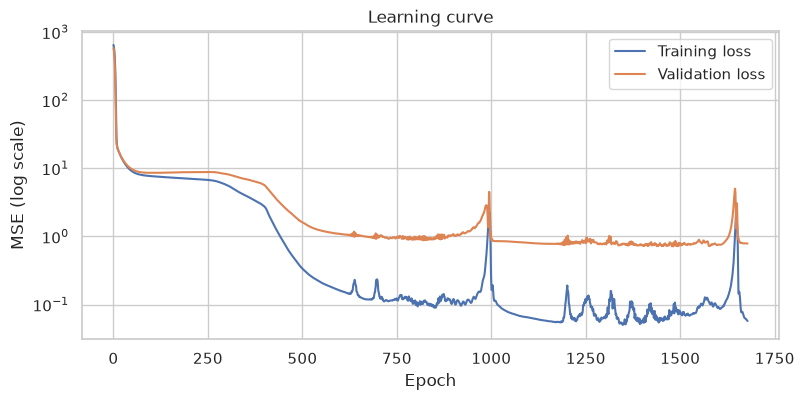

In [32]:
plt.figure(figsize=(9, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("MSE (log scale)")
plt.title("Learning curve")
plt.legend()
plt.show()

As we can see from the graph, in the first **~50 epochs** the MSE of both the training and validation sets drops quickly, showing that the NN learned the basic patterns quickly.

From **~50 to ~300 epochs**, the MSE plateaus at around **8–9**, which is about the same as the Linear Regression MSE from Part 2. Then, from **~300 to ~600 epochs**, there is a second major drop: the training MSE falls below to **0.3** and the validation MSE falls to about **1**. Here the NN learned the non-linear patterns (shape and orientation effects) that the linear models could not capture.

This plateau is why we used a large patience (**200**) for Early Stopping. With a small patience (e.g. **30**), training would have stopped during the plateau, and the NN would have stayed at the level of the linear models, before learning the non-linear patterns in the second drop.

At the end of training (**1679 epochs**), the training MSE is **~0.1** and the validation MSE is **~0.8**. This implies that the NN performs better on the training buildings than on new ones, i.e. slight overfitting. Still, the validation MSE of **~0.8** is about **10 times** lower than the MSE of Linear Regression (**8.25** for heating and **9.73** for cooling, Part 2).

### 4. Evaluate on the test set and compare with Part 2

In [33]:
nn_predict = model.predict(X_test_scaled, verbose=0)

nn_row = {
    "Model": "Neural Network",
    "MSE (Heating)": mean_squared_error(y_test["Heating_Load"], nn_predict[:, 0]),
    "R² (Heating)": r2_score(y_test["Heating_Load"], nn_predict[:, 0]),
    "MSE (Cooling)": mean_squared_error(y_test["Cooling_Load"], nn_predict[:, 1]),
    "R² (Cooling)": r2_score(y_test["Cooling_Load"], nn_predict[:, 1])
}

nn_predict_table = pd.DataFrame([nn_row])

display(nn_predict_table.round(4))

comparison = pd.concat([results_df, nn_predict_table], ignore_index=True).round(4)
display(comparison)

,Model,MSE (Heating),R² (Heating),MSE (Cooling),R² (Cooling)
0,Neural Network,0.416,0.996,1.4068,0.9848


,Model,MSE (Heating),R² (Heating),MSE (Cooling),R² (Cooling)
0,Linear Regression,8.2501,0.9208,9.7329,0.8950
1,Ridge Regression,8.3514,0.9199,9.7943,0.8943
2,Lasso Regression,10.1864,0.9023,10.7958,0.8835
3,Neural Network,0.4160,0.9960,1.4068,0.9848


The **neural network** clearly outperforms all linear models on the test set:
- **R² = 0.996** for heating (MSE **0.42** vs **8.25** for Linear Regression, about **20 times** lower)
- **R² = 0.985** for cooling (MSE **1.41** vs **9.73**, about **7 times** lower). 

**Cooling** remains harder to predict than heating, but the NN captures most of the **non-linear shape and orientation effects** that the linear models missed.

---

Now, we will plot a predicted vs actual values for **Linear Regression** and the **Neural Network** side by side, for both heating and cooling. Points on the dashed diagonal will be perfect predictions, so this shows where the NN improves on the linear model.

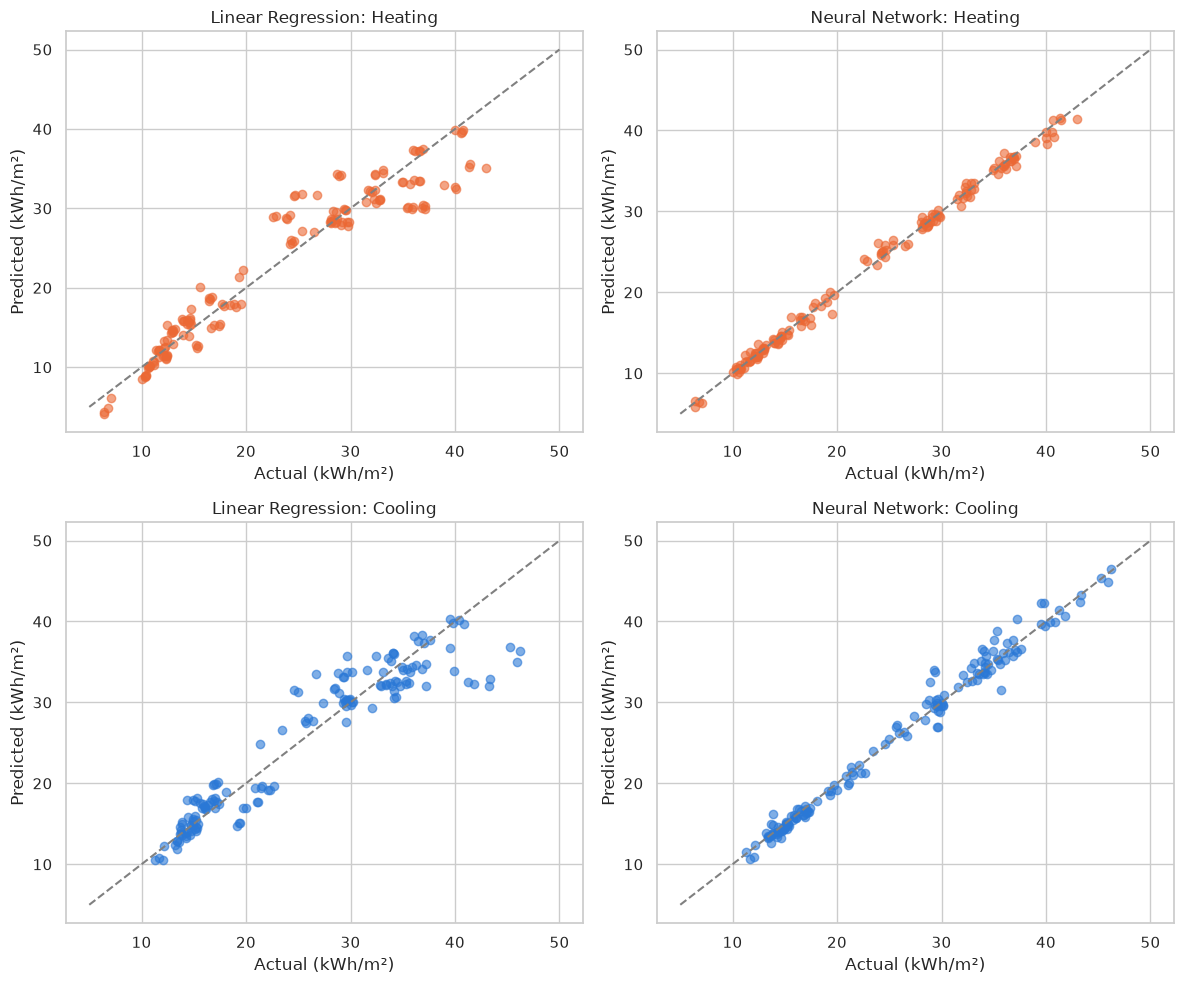

In [34]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].scatter(actual_heat, predicted_heat, alpha=0.6, color=HEAT)
axes[0, 0].set_title("Linear Regression: Heating")

axes[0, 1].scatter(actual_heat, nn_predict[:, 0], alpha=0.6, color=HEAT)
axes[0, 1].set_title("Neural Network: Heating")

axes[1, 0].scatter(actual_cool, predicted_cool, alpha=0.6, color=COOL)
axes[1, 0].set_title("Linear Regression: Cooling")

axes[1, 1].scatter(actual_cool, nn_predict[:, 1], alpha=0.6, color=COOL)
axes[1, 1].set_title("Neural Network: Cooling")

for ax in axes.flat:                                   
    ax.plot([5, 50], [5, 50], "--", color="gray")      
    ax.set_xlabel("Actual (kWh/m²)")
    ax.set_ylabel("Predicted (kWh/m²)")

plt.tight_layout(); plt.show()

The NN predictions lie much closer to the diagonal than those of Linear Regression. 

- For **heating**, the points follow the line almost perfectly across the whole range (**~6–43 kWh/m²**). 
- For **cooling**, the spread is much smaller than for Linear Regression, and the highest-load buildings (**~40–46 kWh/m²**), which Linear Regression strongly **underpredicted**, are now predicted correctly. 

Some spread remains for cooling between **~30 and 40 kWh/m²**, matching its slightly lower R² (**0.985** vs **0.996** for heating).

---

We will now compare the **MSE** per building shape for **Linear Regression** and the **NN**, to check whether the **NN** fixes the large errors for shapes **0.79** and **0.82** found in Part 2.

In [35]:
shape_errors = pd.DataFrame({
    "shape":      X_test["Relative_Compactness"].values,
    "LR heating": (actual_heat - predicted_heat).abs().values,
    "NN heating": (actual_heat - nn_predict[:, 0]).abs().values,
    "LR cooling": (actual_cool - predicted_cool).abs().values,
    "NN cooling": (actual_cool - nn_predict[:, 1]).abs().values,
})

shape_errors.groupby("shape").mean().round(2)

,LR heating,NN heating,LR cooling,NN cooling
shape,,,,
0.62,1.70,0.22,2.78,0.57
0.64,1.56,0.61,3.06,0.59
0.66,1.25,0.31,0.91,0.66
0.69,1.13,0.36,0.89,0.55
0.71,1.00,0.37,0.64,0.51
0.74,1.02,0.26,0.63,0.32
0.76,1.35,0.76,1.35,1.06
0.79,6.47,0.66,6.10,1.16
0.82,5.79,0.69,4.42,1.71


The NN removes the shape-specific errors of the linear model. 

- For shape **0.79**, the mean error drops from **6.47 to 0.66** (heating) and from **6.10 to 1.16** (cooling).
- For shape **0.82**, from **5.79 to 0.69** (heating) and from **4.42 to 1.71** (cooling). 

The NN has a lower error than Linear Regression for **all 12 shapes** and both targets. Its largest remaining error is for **cooling of shape 0.82 (1.71)**, the hardest case, where cooling depends strongly on orientation.

---

Now, we will predict the same new building from Part 2 **(30% glazing)** with the NN and compare it with Linear Regression and with the same building at **25%** and **40%** glazing.

In [36]:
nn_new = model.predict(new_scaled, verbose=0)

print(f"NN heating: {nn_new[0, 0]:.2f}   (LR: 30.61)")
print(f"NN cooling: {nn_new[0, 1]:.2f}   (LR: 32.28)")

display(same_building[["Glazing_Area", "Heating_Load", "Cooling_Load"]])

NN heating: 29.64   (LR: 30.61)
NN cooling: 28.66   (LR: 32.28)


,Glazing_Area,Heating_Load,Cooling_Load
154,0.10,26.89,25.90
394,0.25,29.43,28.38
634,0.40,32.05,30.11


For the new building (30% glazing):

- The NN predicts **29.64** (heating) and **28.66 kWh/m²** (cooling). 

Both values lie between the 25% and 40% of same buildings glazing (heating **29.43–32.05**, cooling **28.38–30.11**). 
Unlike Linear Regression, whose cooling prediction (**32.28**) was higher than both neighbours, the NN gives a **plausible cooling prediction**, showcasing that it has learned the orientation and glazing effects for this shape.

### 5. Log experiments, parameters and metrics with MLflow

We will log our NN as an MLflow run in the experiment **"Energy Efficiency Regression"**. Each run will store the **parameters**:

1. Architecture
2. Training settings

the **metrics**
1. Test MSE and R² for heating and cooling
2. Best validation loss

the **learning curve** as an image, and the **trained model**. This keeps a permanent record of every experiment, so we can compare results from different settings.

2026/11/21 17:19:35 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.


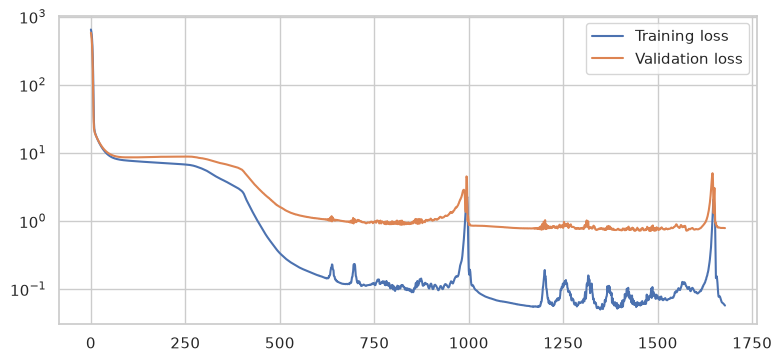

In [37]:
import mlflow

mlflow.set_experiment("Energy Efficiency Regression")

with mlflow.start_run(run_name = "NN 64-32"):
    mlflow.log_params({
        "hidden_layers": "64-32",
        "activation": "relu",
        "optimizer": "adam",
        "learning_rate": 0.001,
        "batch_size": 32,
        "epochs": 2000,
        "patience": 200,
        "validation_split": 0.2,
        "epochs_run": len(history.history["loss"])
    })

    mlflow.log_metrics({
        "test_mse_heating": nn_row["MSE (Heating)"],
        "test_r2_heating": nn_row["R² (Heating)"],
        "test_mse_cooling": nn_row["MSE (Cooling)"],
        "test_r2_cooling": nn_row["R² (Cooling)"],
        "best_val_loss": min(history.history["val_loss"]),
    })

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(history.history["loss"], label="Training loss")
    ax.plot(history.history["val_loss"], label="Validation loss")
    ax.set_yscale("log"); ax.legend()
    mlflow.log_figure(fig, "learning_curve.png")

    mlflow.keras.log_model(model, name="model")


To view the runs, start the MLflow UI from the project folder in a terminal, activate the venv and then run:

`mlflow ui --backend-store-uri sqlite:///mlflow.db`

and open **http://127.0.0.1:5000** in a browser.

### 6. Tune hyperparameters with GridSearchCV

GridSearchCV needs to build a **fresh model** for every combination and fold, and it only works with scikit-learn-style models. 

We will define a function `build_model()` that creates the network for given **hidden-layer sizes** and **learning rate**, and wrap it with **scikeras' `KerasRegressor`**, so it behaves like a scikit-learn model (`fit`, `predict`, `score`). 

The training settings will be the same as before (up to **2000 epochs**, Early Stopping with **patience 200**, **20%** validation split).

In [38]:
from scikeras.wrappers import KerasRegressor

def build_model(hidden_layers=(64, 32), learning_rate=0.001):
    model = keras.Sequential(
        [keras.Input(shape=(X_train_scaled.shape[1],))]
        + [layers.Dense(u, activation="relu") for u in hidden_layers]
        + [layers.Dense(2)]
    )
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate), loss="mse")
    return model

early_stop_gs = keras.callbacks.EarlyStopping(monitor="val_loss", patience=200, restore_best_weights=True)

nn_reg = KerasRegressor(
    model=build_model,          
    epochs=2000,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop_gs],
    verbose=0,
    random_state=42,
)

build_model().summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 2)              │            66 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,042 (11.88 KB)

 Trainable params: 3,042 (11.88 KB)

 Non-trainable params: 0 (0.00 B)

---

We will tune the two settings with the largest expected impact: the **hidden-layer sizes** ((32, 16) vs (64, 32)), since our initial architecture was a guess, and the **learning rate** (0.001 vs 0.01), which controls how quickly the network escapes the plateau seen in the learning curve. 

This will give **4 combinations**, each evaluated with **3-fold cross-validation** on the training set only (**12 trainings**), scored by R². 

In [39]:
import time
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__hidden_layers": [(32,16), (64,32)],
    "model__learning_rate": [0.001,0.01],
}

gs = GridSearchCV(nn_reg, param_grid, cv=3, scoring="r2", n_jobs=1, refit=True)

start = time.time()
gs.fit(X_train_scaled,y_train)
print(f"Took {(time.time() - start) / 60:.1f} minutes")

print("Best settings:", gs.best_params_)
print("Best CV R²:", round(gs.best_score_, 4))

E0000 00:00:1795278023.428450    5399 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795278059.075200    5399 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

E0000 00:00:1795278097.369296    5399 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


E0000 00:00:1795278132.382667    5399 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}
E0000 00:00:1795278154.364580    5399 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),

Took 11.2 minutes
Best settings: {'model__hidden_layers': (64, 32), 'model__learning_rate': 0.01}
Best CV R²: 0.9481


The search took **11.2 minutes**. The best combination is **(64, 32) hidden layers with a learning rate of 0.01**, with a mean CV R² of **0.948**. 

The architecture matches our initial choice, but a **10× larger learning rate** works better, as it helps the network escape the plateau faster. 

The important thing to note here is that the **CV R²** is **lower** than the **test R²** from previous section 4 (**0.996**), because each CV model is trained on only **two-thirds** of the training data. 

The trainings ran one at a time (`n_jobs=1`), since running several TensorFlow trainings in parallel (`n_jobs=-1`) overloaded the laptop.

---

Now, that the training is complete, we will create a table to compare how each combination performed and depending on their values, we will decide which combination will suit our dataset best.

In [40]:
gs_results = pd.DataFrame(gs.cv_results_)[[
    "param_model__hidden_layers",
    "param_model__learning_rate",
    "mean_test_score",
    "std_test_score",
    "mean_fit_time",
    "rank_test_score"
]].sort_values("rank_test_score")

display(gs_results.round(4))

,param_model__hidden_layers,param_model__learning_rate,mean_test_score,std_test_score,mean_fit_time,rank_test_score
3,"(64, 32)",0.010,0.9481,0.0477,88.1250,1
1,"(32, 16)",0.010,0.9031,0.0363,37.5932,2
2,"(64, 32)",0.001,0.8849,0.0059,29.4038,3
0,"(32, 16)",0.001,0.8829,0.0041,36.1943,4


Based on this table, the combination of hidden layers **(64,32)** with learning rate of **0.01** performed well as it's mean test score is highest.

Now, we know our best NN model is the one with learning rate of **0.01** but still this needs to be verified on our **Test Data**.

---

Now, we need to log the results of all combinations on MLflow. We will be using a for loop to avoid writing redundant code.

In [41]:
with mlflow.start_run(run_name="GridSearchCV"):
    mlflow.log_params({
        "cv_folds": 3,
        "scoring": "r2",
        "max_epochs": 2000,
        "patience": 200,
        "best_hidden_layers": str(gs.best_params_["model__hidden_layers"]),
        "best_learning_rate": gs.best_params_["model__learning_rate"],
    })
    mlflow.log_metric("best_cv_r2", gs.best_score_)

    for _, row in gs_results.iterrows():
        hl = row["param_model__hidden_layers"]
        lr_value = row["param_model__learning_rate"]

        with mlflow.start_run(run_name=f"GS {hl} lr={lr_value}", nested=True):
            mlflow.log_params({"hidden_layers": str(hl), "learning_rate": lr_value})
            mlflow.log_metrics({
                "mean_cv_r2":      row["mean_test_score"],
                "std_cv_r2":       row["std_test_score"],
                "mean_fit_time_s": row["mean_fit_time"],
            })

---

Now that the combinations are logged, we need to test our **best_nn** on our **test_data** and see how well it performs on it.

We will create a table which will list all the models tested so far including:
1. Linear Regression.
2. Ridge.
3. Lasso.
4. NN
5. GridSearch NN

In [42]:
best_nn = gs.best_estimator_
gs_pred = best_nn.predict(X_test_scaled)

gs_row = {
    "Model": "NN (GridSearch best)",
    "MSE (Heating)": mean_squared_error(y_test["Heating_Load"], gs_pred[:, 0]),
    "R² (Heating)":  r2_score(y_test["Heating_Load"], gs_pred[:, 0]),
    "MSE (Cooling)": mean_squared_error(y_test["Cooling_Load"], gs_pred[:, 1]),
    "R² (Cooling)":  r2_score(y_test["Cooling_Load"], gs_pred[:, 1]),
}

final_comparison = pd.concat([comparison, pd.DataFrame([gs_row])], ignore_index=True)
display(final_comparison.round(4))

,Model,MSE (Heating),R² (Heating),MSE (Cooling),R² (Cooling)
0,Linear Regression,8.2501,0.9208,9.7329,0.8950
1,Ridge Regression,8.3514,0.9199,9.7943,0.8943
2,Lasso Regression,10.1864,0.9023,10.7958,0.8835
3,Neural Network,0.4160,0.9960,1.4068,0.9848
4,NN (GridSearch best),0.4880,0.9953,1.0264,0.9889


The results are pretty interesting. Our NN works best for the **Heating Energy** and our **GridSearch NN** works best for the **Cooling Energy**. Now the question is which one to choose?

The answer is pretty simple. If we look at the values, the predictions of the **Heating Energy** by both NN and GridSearch NN are realtively close i.e. a difference of **~0.7 kWh/m²** which means either one can be selected, which leaves **Cooling Energy** predictions to be the ones to make the final call. If we see it, we will notice that **MSE of Cooling** for NN is **1.40** and for GridSearch NN is **1.02** i.e. GridSearch NN predicted Cooling MSE **~27%** much better.

So the avergae MSE of **NN** is **0.91** and **GridSearch NN** is **0.76**. Hence, GridSearch NN is better overall.

---

Now, we need to log the GridSearch NN model in MLflow as well.

In [43]:
with mlflow.start_run(run_name="NN GridSearch best"):
    mlflow.log_params({
        "hidden_layers": str(gs.best_params_["model__hidden_layers"]),
        "learning_rate": gs.best_params_["model__learning_rate"],
        "batch_size": 32,
        "max_epochs": 2000,
        "patience": 200,
    })
    mlflow.log_metrics({
        "test_mse_heating": gs_row["MSE (Heating)"],
        "test_r2_heating":  gs_row["R² (Heating)"],
        "test_mse_cooling": gs_row["MSE (Cooling)"],
        "test_r2_cooling":  gs_row["R² (Cooling)"],
    })
    mlflow.keras.log_model(best_nn.model_, name="model")

2026/11/21 18:38:20 WARNING mlflow.keras.save: You are saving a Keras model without specifying model signature.


### 7. Saving the final model

We will save everything the deployment app needs to make predictions outside this notebook: 

1. The **best model from GridSearchCV** (`app/model.keras`)
2. The **fitted scaler** from the training set (`app/scaler.joblib`)
3. The **list of the 13 feature columns** in their training order (`app/feature_columns.joblib`)

which is needed to one-hot encode new inputs in the same way.

In [44]:
import joblib
best_nn.model_.save("app/model.keras")                   
joblib.dump(scaler,"app/scaler.joblib")               
joblib.dump(list(X_train.columns), "app/feature_columns.joblib")

['app/feature_columns.joblib']

In [45]:
loaded_model   = keras.models.load_model("app/model.keras")
loaded_scaler  = joblib.load("app/scaler.joblib")
loaded_columns = joblib.load("app/feature_columns.joblib")

print(loaded_columns == list(X_train.columns))
print(loaded_model.predict(loaded_scaler.transform(new_X), verbose=0))
print(best_nn.predict(new_scaled))

True
[[30.197392 28.448322]]
[[30.197392 28.448322]]


Reloading the saved files and predicting the new building from Part 2 gives exactly the same result as the original model (**30.20** heating, **28.45 kWh/m²** cooling), confirming that the model, scaler and column list were saved correctly. 

Both values are also perfect i.e. lying between the same building's loads at 25% and 40% glazing.

---


---

## 4. Deployment

We will be using **Streamlit** for the deployment, so we'll be doing the setup.

In [46]:
%pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 5.0 MB/s  0:00:02m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.2/797.2 kB 6.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 8.9 MB/s  0:00:01m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [streamlit]/5 [streamlit]
Note: you may need to restart the kernel to use updated packages.


In [47]:
import streamlit
print(streamlit.__version__)

1.67.0


---

### 4.1 Predicting unseen buildings

We will define a function `predict_building()` that loads nothing from the notebook's training variables: it uses only the **saved files** (model, scaler and feature columns) - the one our  deployed app will use. 

- It one-hot encodes the input, aligns it with the 13 training columns.
- It scales it with the training scaler, and returns the predicted heating and cooling load.

We will then test it on three new buildings with glazing areas not present in the dataset.

In [48]:
def predict_building(building):
    new = pd.DataFrame([building])                                            
    new_X = pd.get_dummies(new, columns=["Orientation", "Glazing_Area_Distribution"], dtype=int)
    new_X = new_X.reindex(columns=loaded_columns, fill_value=0)                   
    new_scaled = loaded_scaler.transform(new_X)                                  
    pred = loaded_model.predict(new_scaled, verbose=0)                          
    return float(pred[0, 0]), float(pred[0, 1])                               

Test it on three new buildings with glazing areas not present in the dataset.

In [49]:
new_buildings = [
    {"Relative_Compactness": 0.98, "Wall_Area": 294.0, "Roof_Area": 110.25, "Overall_Height": 7.0,
     "Orientation": 3, "Glazing_Area": 0.15, "Glazing_Area_Distribution": 1},
    {"Relative_Compactness": 0.62, "Wall_Area": 367.5, "Roof_Area": 220.5, "Overall_Height": 3.5,
     "Orientation": 5, "Glazing_Area": 0.30, "Glazing_Area_Distribution": 2},
    {"Relative_Compactness": 0.86, "Wall_Area": 294.0, "Roof_Area": 147.0, "Overall_Height": 7.0,
     "Orientation": 4, "Glazing_Area": 0.30, "Glazing_Area_Distribution": 3},
]

for b in new_buildings:
    heat, cool = predict_building(b)
    print(f"Shape {b['Relative_Compactness']}, glazing {b['Glazing_Area']}: "
          f"heating {heat:.2f}, cooling {cool:.2f} kWh/m²")

Shape 0.98, glazing 0.15: heating 25.55, cooling 26.63 kWh/m²
Shape 0.62, glazing 0.3: heating 15.71, cooling 15.85 kWh/m²
Shape 0.86, glazing 0.3: heating 30.20, cooling 28.45 kWh/m²


The function now correctly reproduces the results for the building with 30% glazing (**30.20 / 28.45 kWh/m²**), confirming it works correctly with the saved files. 

The tall building (Shape 0.86) needs about **10 kWh/m²** more heating than the short one (Shape 0.62), confirming that height is the dominant factor. 

All predictions lie between the values of the same buildings at the neighbouring glazing levels in the dataset, so they are almost perfect.

### 4.2 Deployed App

In [ ]:
%%writefile app/app.py
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"

from pathlib import Path
import joblib
import keras
import pandas as pd
import streamlit as st

APP_DIR = Path(__file__).parent

@st.cache_resource
def load_artifacts():
    model   = keras.models.load_model(APP_DIR / "model.keras")
    scaler  = joblib.load(APP_DIR / "scaler.joblib")
    columns = joblib.load(APP_DIR / "feature_columns.joblib")
    return model, scaler, columns

model, scaler, columns = load_artifacts()

st.title("Building Energy Load Predictor")
st.success("Model loaded")

DATA_FILE = APP_DIR.parent / "data" / "energy_efficiency_data.csv"

@st.cache_data
def load_shapes():
    df = pd.read_csv(DATA_FILE)
    return df.groupby("Relative_Compactness")[["Wall_Area", "Roof_Area", "Overall_Height"]].first()

shapes = load_shapes()

ORIENT = {"North": 2, "East": 3, "South": 4, "West": 5}
DIST   = {"Uniform": 1, "North": 2, "East": 3, "South": 4, "West": 5}

rc  = st.selectbox("Building shape (relative compactness)", shapes.index.tolist())
geo = shapes.loc[rc]
st.caption(f"Height {geo['Overall_Height']} m · wall {geo['Wall_Area']} m² · roof {geo['Roof_Area']} m²")

orientation  = st.selectbox("Orientation", list(ORIENT.keys()))
glazing      = st.slider("Glazing area (share of floor area)", 0.0, 0.40, 0.25, 0.05)
distribution = st.selectbox("Glazing distribution", list(DIST.keys()), disabled=(glazing == 0))

def predict_building(building):
    new = pd.DataFrame([building])
    new_X = pd.get_dummies(new, columns=["Orientation", "Glazing_Area_Distribution"], dtype=int)
    new_X = new_X.reindex(columns=columns, fill_value=0)
    new_scaled = scaler.transform(new_X)
    pred = model.predict(new_scaled, verbose=0)
    return float(pred[0, 0]), float(pred[0, 1])

if st.button("Predict"):
    building = {
        "Relative_Compactness": rc,
        "Wall_Area": geo["Wall_Area"],
        "Roof_Area": geo["Roof_Area"],
        "Overall_Height": geo["Overall_Height"],
        "Orientation": ORIENT[orientation],
        "Glazing_Area": glazing,
        "Glazing_Area_Distribution": 0 if glazing == 0 else DIST[distribution],
    }
    heat, cool = predict_building(building)

    c1, c2 = st.columns(2)
    c1.metric("Heating load", f"{heat:.2f} kWh/m²")
    c2.metric("Cooling load", f"{cool:.2f} kWh/m²")

![alt text](image.png)

For the test building (shape **0.86**, South-facing, **30%** glazing, mostly on the East side), the app predicts **30.20 kWh/m²** heating and **28.45 kWh/m²** cooling, exactly matching the prediction in Section 4.1. 

This confirms that the deployed app uses the same model and preprocessing as the notebook.